# Fig9 Radar Chart

**Figure 9** — Radar chart: multi-metric comparison of 5 cities.

Run this notebook to reproduce Figure 9 for the manuscript (3000×1800 px, 150 DPI).

> **Run cells in order: Cell 1 → Cell 2 → Cell 3**

In [1]:
# Install / upgrade required libraries
!pip install matplotlib numpy pandas scikit-learn -q



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Global constants (real project results) ──
DPI   = 150
W_IN  = 3000 / DPI   # 20 inches
H_IN  = 1800 / DPI   # 12 inches
BG    = '#F7F9FC'

CITIES        = ['Riyadh', 'Jeddah', 'Abha', 'Dammam', 'Qassim']
SEASONS       = ['Spring', 'Summer', 'Autumn', 'Winter']
MONTHS        = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
CITY_COLORS   = ['#1F4E79','#2E75B6','#C00000','#ED7D31','#70AD47']
SEASON_COLORS = {'Spring':'#70AD47','Summer':'#ED7D31','Autumn':'#C00000','Winter':'#1F4E79'}

BASELINE = {
    'Riyadh':  dict(rmse=51.68, mae=25.57, r2=0.9747, bias=-4.04,  paper=100.6),
    'Jeddah':  dict(rmse=49.49, mae=25.93, r2=0.9769, bias=-6.20,  paper=101.0),
    'Abha':    dict(rmse=67.70, mae=39.89, r2=0.9562, bias=-8.83,  paper=107.4),
    'Dammam':  dict(rmse=49.19, mae=25.45, r2=0.9758, bias=-3.50,  paper=92.4),
    'Qassim':  dict(rmse=47.28, mae=24.72, r2=0.9785, bias=-0.30,  paper=97.7),
}
META = {
    'Riyadh':  dict(before=4.8,  after=67.1, failures=289),
    'Jeddah':  dict(before=12.5, after=49.2, failures=313),
    'Abha':    dict(before=2.0,  after=77.8, failures=641),
    'Dammam':  dict(before=7.8,  after=52.6, failures=293),
    'Qassim':  dict(before=2.1,  after=59.7, failures=288),
}
SEASONAL_RECALL = {
    'Riyadh':  dict(Spring=4.8,  Summer=0.7,  Autumn=12.2, Winter=15.3),
    'Jeddah':  dict(Spring=4.9,  Summer=3.6,  Autumn=11.0, Winter=16.8),
    'Abha':    dict(Spring=3.8,  Summer=2.3,  Autumn=12.1, Winter=12.4),
    'Dammam':  dict(Spring=5.7,  Summer=0.7,  Autumn=12.1, Winter=16.9),
    'Qassim':  dict(Spring=3.9,  Summer=0.1,  Autumn=12.0, Winter=16.3),
}
print('✓ Setup complete — ready to run figure cell')


✓ Setup complete — ready to run figure cell


## Figure 9 — Radar Chart: Multi-Metric City Comparison
**Purpose:** Compare all 5 cities on 5 performance dimensions simultaneously.  
**Section in paper:** Section 5 — Discussion / Comparative Analysis.  
**Key finding:** Qassim most balanced; Abha paradox (highest recall, lowest R²); Dammam highest winter recall.


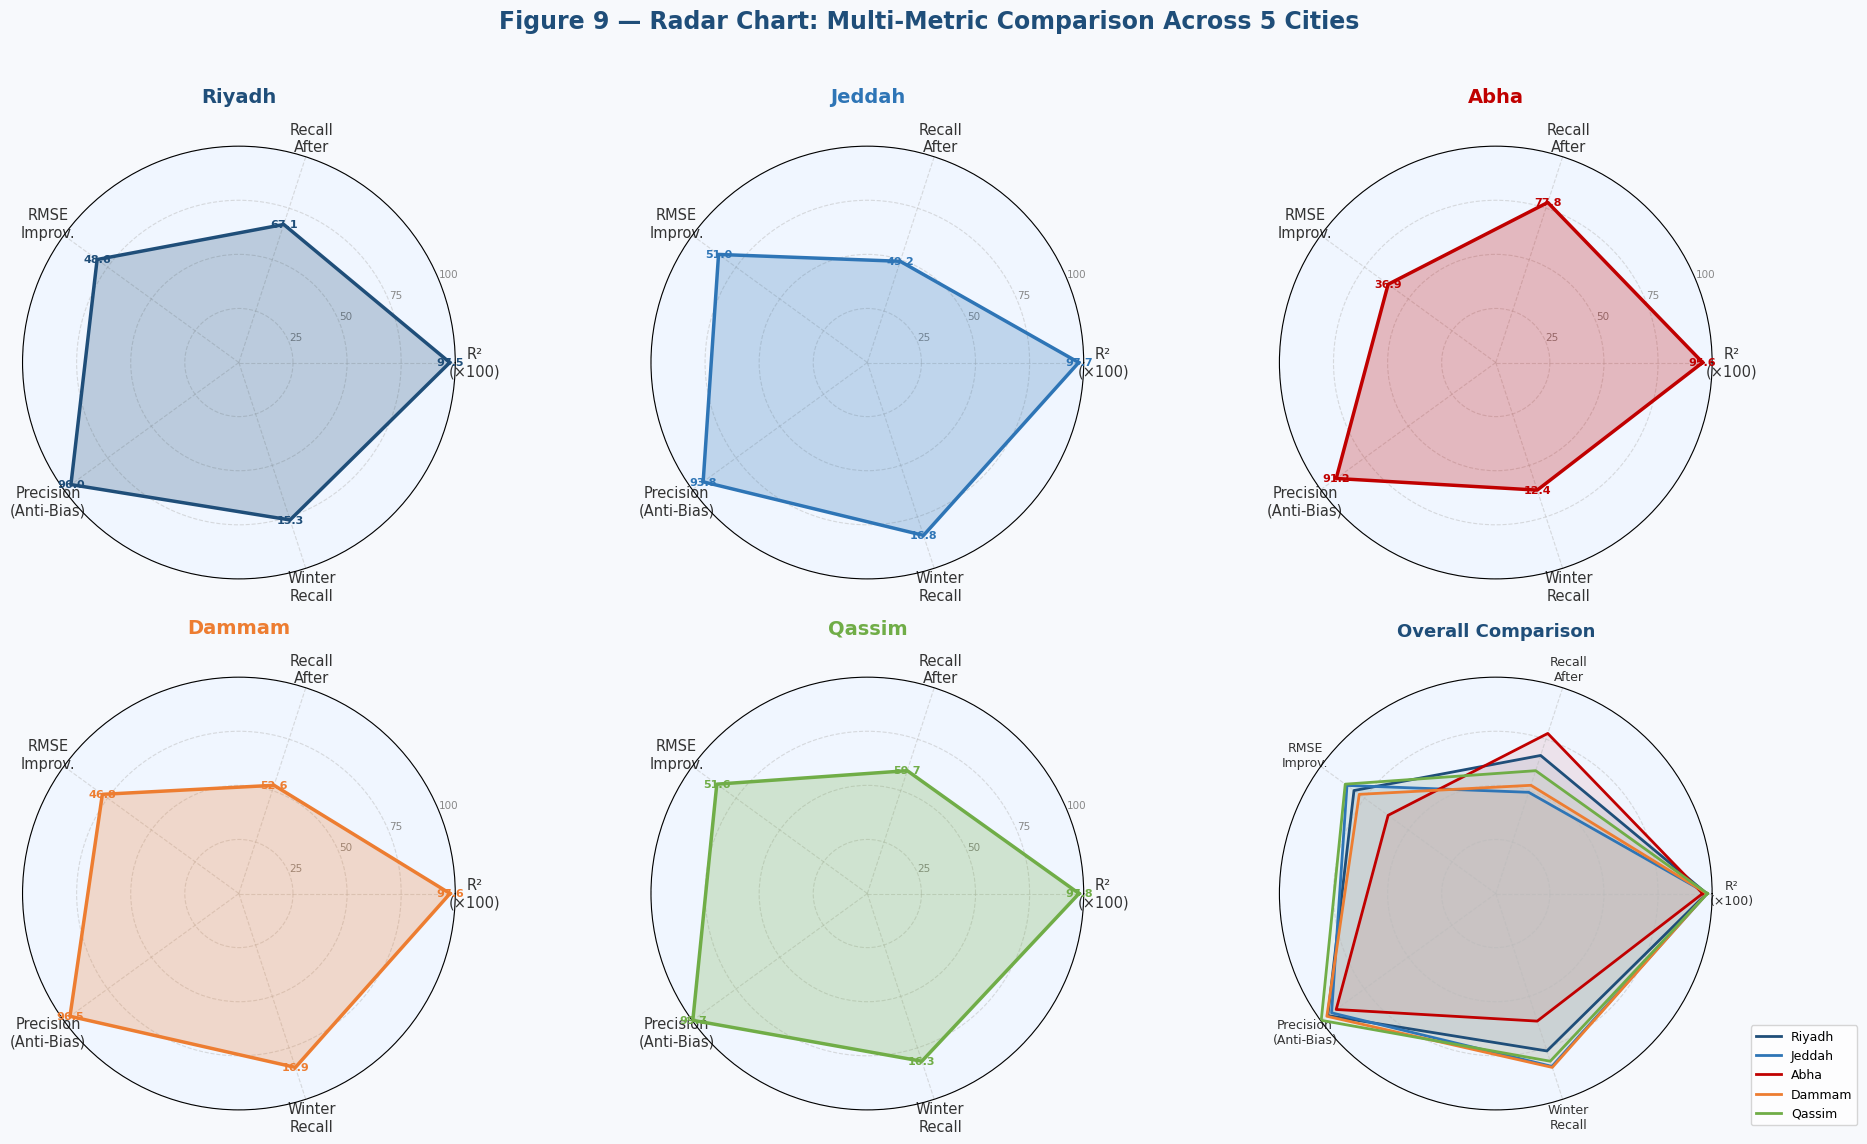

✓ Saved: fig9_radar_chart.png  (3000×1800 px)


In [3]:
metrics_labels = ['R²\n(×100)', 'Recall\nAfter', 'RMSE\nImprov.', 'Precision\n(Anti-Bias)', 'Winter\nRecall']
metrics_max    = [100, 100, 60, 100, 20]
city_metrics = {
    'Riyadh':  [97.47, 67.1, 48.6, 95.96, 15.3],
    'Jeddah':  [97.69, 49.2, 51.0, 93.80, 16.8],
    'Abha':    [95.62, 77.8, 36.9, 91.17, 12.4],
    'Dammam':  [97.58, 52.6, 46.8, 96.50, 16.9],
    'Qassim':  [97.85, 59.7, 51.6, 99.70, 16.3],
}

N      = len(metrics_labels)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist() + \
         np.linspace(0, 2*np.pi, N, endpoint=False).tolist()[:1]

fig, axes = plt.subplots(2, 3, figsize=(W_IN, H_IN), subplot_kw=dict(polar=True))
fig.patch.set_facecolor(BG)
fig.suptitle('Figure 9 — Radar Chart: Multi-Metric Comparison Across 5 Cities',
             fontsize=17, fontweight='bold', color='#1F4E79', y=0.97)

axs = axes.flatten()
for ai, (city, col) in enumerate(zip(CITIES, CITY_COLORS)):
    ax = axs[ai]; ax.set_facecolor('#F0F6FF')
    vals_norm = [v/m*100 for v,m in zip(city_metrics[city], metrics_max)] + \
                [city_metrics[city][0]/metrics_max[0]*100]
    ax.plot(angles, vals_norm, color=col, lw=2.5, zorder=4)
    ax.fill(angles, vals_norm, color=col, alpha=0.25, zorder=3)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics_labels, fontsize=10.5, color='#333')
    ax.set_ylim(0,100); ax.set_yticks([25,50,75,100])
    ax.set_yticklabels(['25','50','75','100'], fontsize=7.5, color='#888')
    ax.set_title(city, fontsize=14, fontweight='bold', color=col, pad=14)
    ax.grid(color='#bbb', linestyle='--', alpha=0.5)
    for angle, val_n, val_r in zip(angles[:-1], vals_norm[:-1], city_metrics[city]):
        ax.annotate(f'{val_r:.1f}', xy=(angle, val_n), fontsize=8, color=col,
                    fontweight='bold', ha='center', va='center')

# Combined overlay
ax_all = axs[5]; ax_all.set_facecolor('#F0F6FF')
for city, col in zip(CITIES, CITY_COLORS):
    vals_norm = [v/m*100 for v,m in zip(city_metrics[city], metrics_max)] + \
                [city_metrics[city][0]/metrics_max[0]*100]
    ax_all.plot(angles, vals_norm, color=col, lw=2, label=city, zorder=4)
    ax_all.fill(angles, vals_norm, color=col, alpha=0.08)
ax_all.set_xticks(angles[:-1])
ax_all.set_xticklabels(metrics_labels, fontsize=9, color='#333')
ax_all.set_ylim(0,100); ax_all.set_yticks([25,50,75,100])
ax_all.set_yticklabels(['','','',''], fontsize=7)
ax_all.set_title('Overall Comparison', fontsize=13, fontweight='bold', color='#1F4E79', pad=14)
ax_all.legend(loc='lower right', fontsize=9, bbox_to_anchor=(1.35,-0.05))
ax_all.grid(color='#bbb', linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.savefig('fig9_radar_chart.png', dpi=DPI, bbox_inches='tight', facecolor=BG)
plt.show()
print('✓ Saved: fig9_radar_chart.png  (3000×1800 px)')
